<div align="center" style="text-align: center; padding: 50px 0; border-top: 4px solid #1f4e79; border-bottom: 4px solid #1f4e79;">

<h1 style="text-align: center; color: #1f4e79; margin-bottom: 8px;">Forecasting US Electricity and Gas Output</h1>

<h3 style="text-align: center; color: #555; font-weight: normal;">Time Series Analysis: ETS + ARIMA vs Facebook Prophet</h3>

<br>

<p style="text-align: center; font-size: 16px;"><b>Author:</b> Tanguy Mandrillon &nbsp;|&nbsp; <b>Year:</b> 2026</p>

</div>


> **Note on AI usage:** AI (Claude Code) was used as an assistant to write the code of this notebook, to draft the text and to design the layout (title page, table of contents and plot style). The analysis was led by me. Details and prompts are in section 4.

# Introduction

In this notebook, we analyze a time series and forecast it with two different methods.

In the first approach, we apply an ETS decomposition to split the series into its trend, seasonal and residual components. The trend and seasonality are extrapolated, while the residual $R_t$ is modeled with an ARIMA model. We then recombine the three components to obtain the final forecast and compare it with the test set.

The second approach uses Facebook Prophet, a more automated method, to produce the same forecast.

Finally, we compare both approaches using error metrics and draw conclusions.


## Table of contents

| Part | Content |
|---|---|
| **0. Dataset** | Import, plot and train-test split |
| **1. ETS Decomposition + ARIMA** | Model choice, trend, seasonality, residual forecasting, recomposition and errors |
| **2. Facebook Prophet** | Forecasting, errors and parameter tuning |
| **3. Conclusion** | Comparison of both approaches |
| **4. AI-usage policy** | Where AI was used, planning session and prompts |

---


In [1]:
import matplotlib.pyplot as plt

# Global plot style shared by all the figures of the notebook
plt.rcParams.update({
    "figure.dpi": 110,
    "figure.facecolor": "white",
    "axes.facecolor": "#fafafa",
    "axes.grid": True,
    "grid.color": "#dddddd",
    "grid.linestyle": "-",
    "grid.linewidth": 0.6,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#444444",
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "axes.titlepad": 12,
    "axes.labelsize": 11,
    "axes.labelcolor": "#333333",
    "legend.frameon": True,
    "legend.framealpha": 0.9,
    "legend.edgecolor": "#cccccc",
    "legend.fontsize": 9,
    "lines.linewidth": 1.2,
    "font.size": 10,
})


# 0. Dataset
First of all, we need to find a suitable time series (TS). For the analysis to make sense, the TS should have three distinct components: trend, seasonality and residual.

Energy production is a natural candidate: it grows with the economy and the population (trend), and it follows the weather (seasonality), with heating in winter and air conditioning in summer.

We use the [IPG2211A2N](https://fred.stlouisfed.org/series/IPG2211A2N) series from FRED (Federal Reserve Bank of St. Louis): the industrial production index of US electric and gas utilities, monthly, with 2017 = 100, **not seasonally adjusted**. The source is the Industrial Production release (G.17) of the Federal Reserve Board. The seasonally adjusted version must not be used, otherwise the seasonal component we want to study would already be removed.

## 0.1. Import dataset
Let's start by loading the dataset into a pandas DataFrame.

The file `IPG2211A2N.csv` has two columns: `observation_date` (first day of the month) and `IPG2211A2N` (the index). It covers January 1939 to August 2026. We keep **January 1995 onwards** (380 months): 30 years are enough to estimate a stable seasonal profile, and the older decades (much faster growth, oil shocks) say little about today's energy sector. We rename the column to `output`, check that there is no missing value, and set an explicit monthly frequency (`MS`, month start) on the index, which statsmodels needs.

In [2]:
import pandas as pd

raw = pd.read_csv("IPG2211A2N.csv", parse_dates=["observation_date"], index_col="observation_date")

# Monthly output of US electric and gas utilities, index 2017 = 100 (not seasonally adjusted)
df = raw.rename(columns={"IPG2211A2N": "output"})
df.index.name = "date"
# Analysis window: January 1995 onwards
df = df.loc["1995-01-01":]
print(f"Missing values: {df['output'].isna().sum()}")
# Explicit monthly frequency (month start), needed by statsmodels
df = df.asfreq("MS")

df

Missing values: 0


,output
date,
1995-01-01,91.3554
1995-02-01,86.3571
1995-03-01,80.3024
1995-04-01,72.9393
1995-05-01,72.4021
...,...
2026-04-01,94.5652
2026-05-01,97.7156
2026-06-01,110.7733


## 0.2. Plot TS

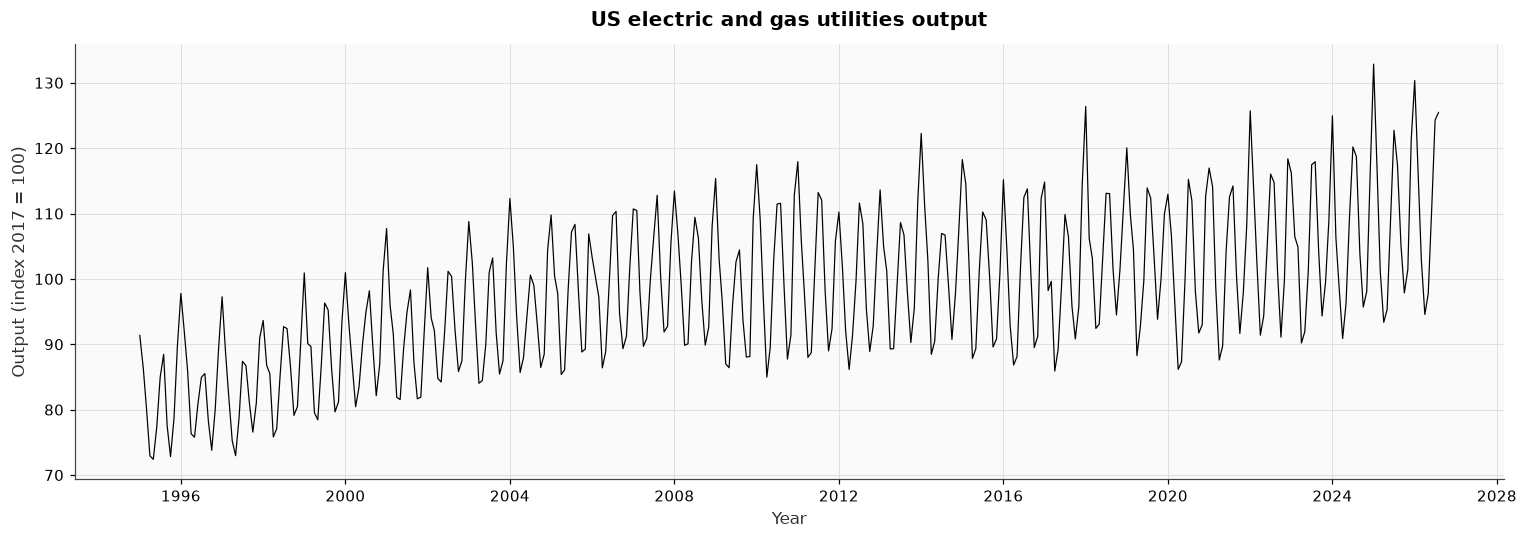

In [3]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(df.index, df.output, color="black", linewidth=0.8)
ax.set_title("US electric and gas utilities output")
ax.set_xlabel("Year")
ax.set_ylabel("Output (index 2017 = 100)")
plt.tight_layout()
plt.show()

> Seasonality?

The series shows a very regular yearly pattern with **two peaks**: a high one in winter (January, heating) and a second one in July-August (air conditioning). The lows are in spring (April-May) and in autumn (October), when there is little need for heating or cooling. The seasonal swings get bigger as the series grows: about 25 points between the highest and the lowest month in the late 1990s, about 35 points in recent years.

> Trend?

The yearly average grows from about 81 in 1995 to about 107 in 2024, but not at a constant speed: fast growth until the mid-2000s, an almost flat level from about 2007 to 2016, then growth again. Unlike retail or transport series, there is no big shock: in 2020 the yearly average only dipped from 104.0 to 101.0. The month-to-month noise mostly comes from the weather (a cold winter or a hot summer).

## 0.3. train-test split
To compute the errors between our forecast and reality, we have to keep a part of the data to test our result. We keep the year 2025 plus the first eight months of 2026 as test set. The train set contains only complete years, which is convenient for the yearly windows used later.

Train-set: January 1995 -> December 2024 (360 months, 30 years)

Test-set: January 2025 -> August 2026 (20 months)

In [4]:
df_train = df.loc[:"2024-12-01"]
df_test = df.loc["2025-01-01":]

print(f"Train: {df_train.index.min():%Y-%m} -> {df_train.index.max():%Y-%m} ({len(df_train)} months)")
print(f"Test:  {df_test.index.min():%Y-%m} -> {df_test.index.max():%Y-%m} ({len(df_test)} months)")

Train: 1995-01 -> 2024-12 (360 months)
Test:  2025-01 -> 2026-08 (20 months)
